Dataset shape: (303, 14)
Data types:
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca              str
thal            str
target        int64
dtype: object
Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64
basic statistics:
              age         sex          cp    trestbps        chol         fbs  \
count  303.000000  303.000000  303.000000  303.000000  303.000000  303.000000   
mean    54.438944    0.679868    3.158416  131.689769  246.693069    0.148515   
std      9.038662    0.467299    0.960126   17.599748   51.776918    0.356198   
min     29.000000    0.000000    1.000000   94.000000  126.000000    0.000000   
25%     48.000000    

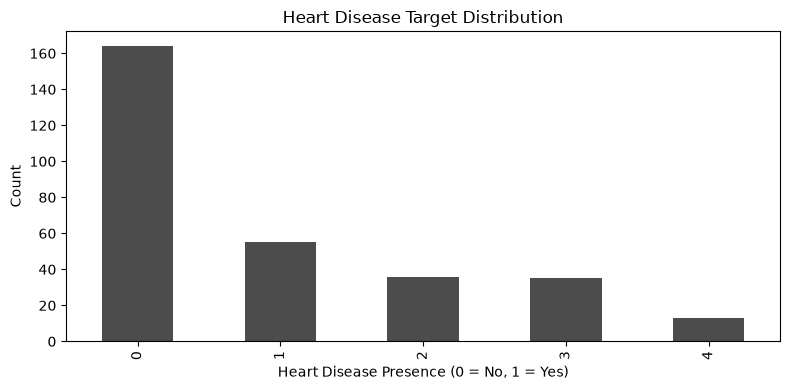

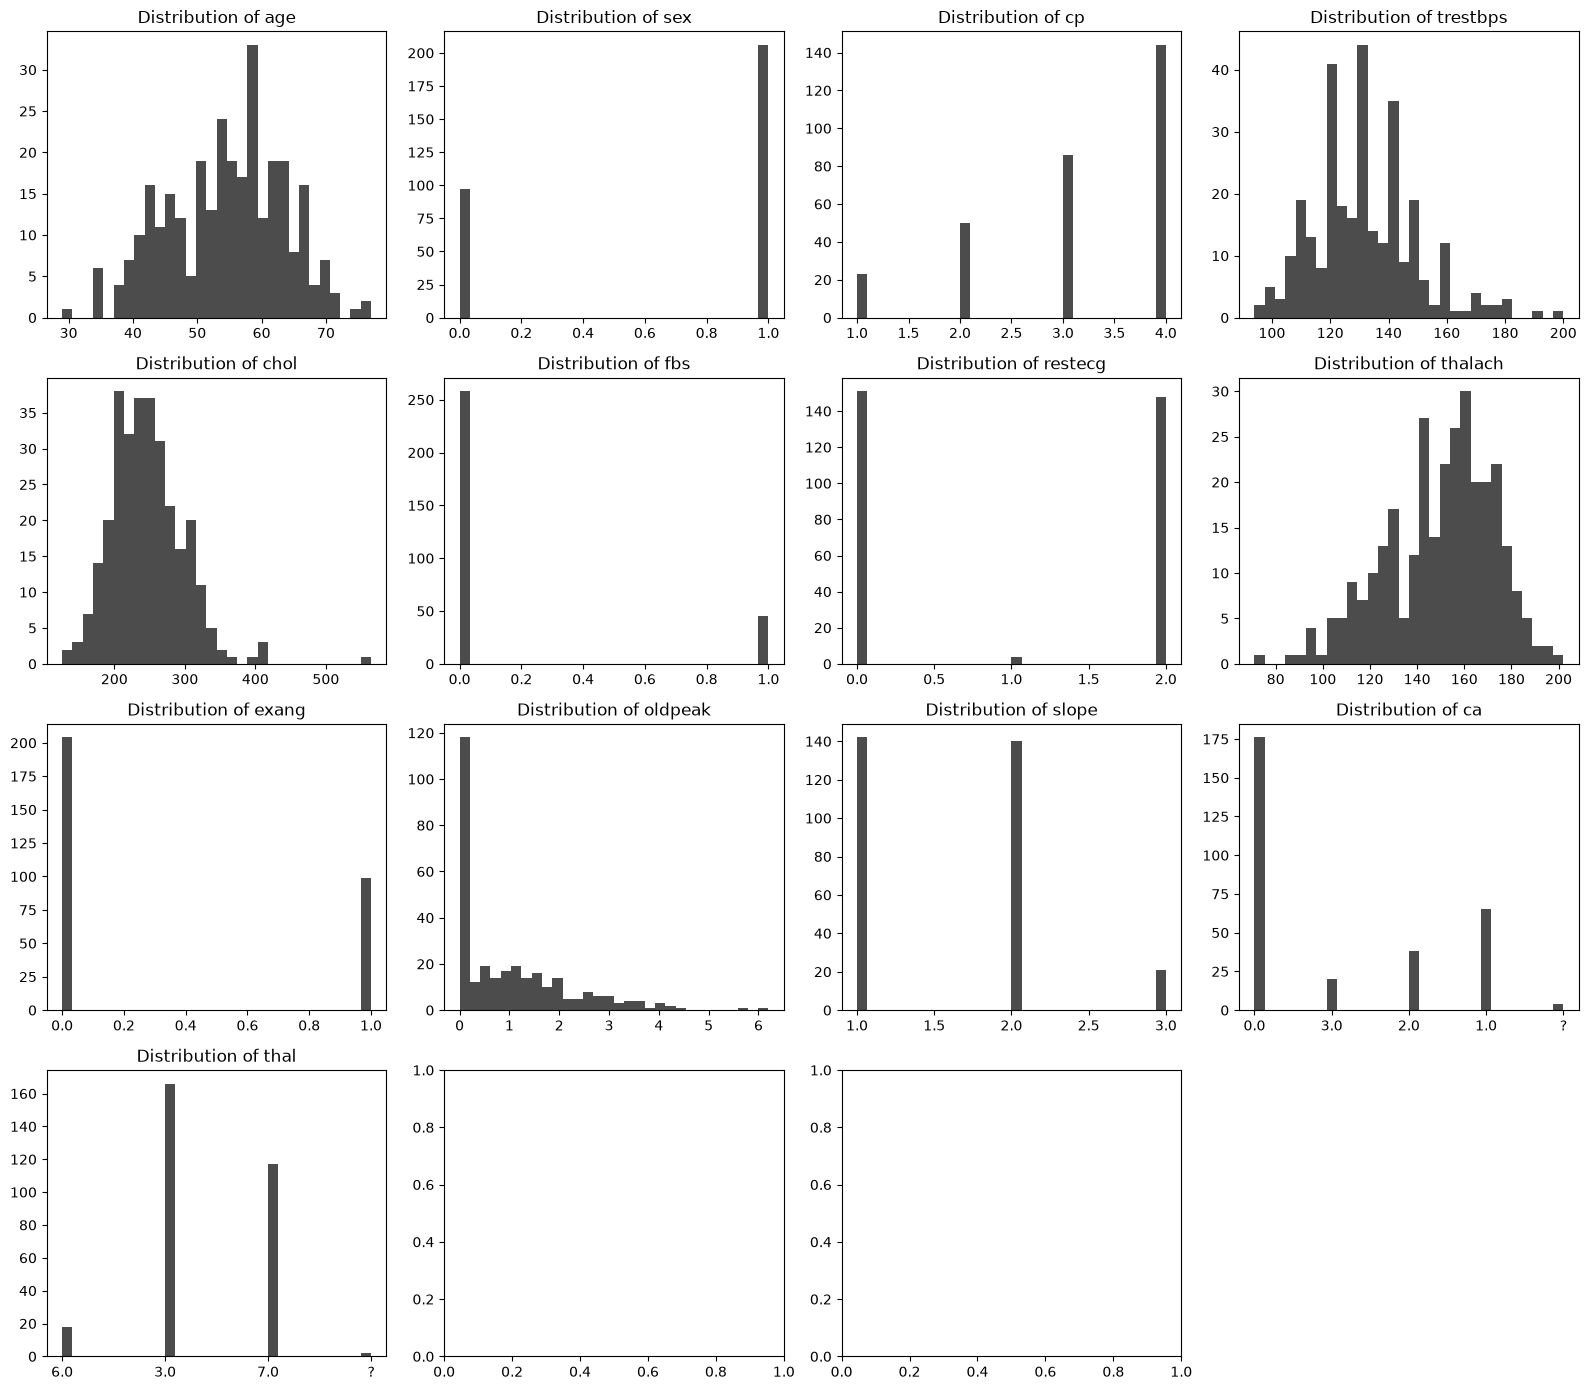

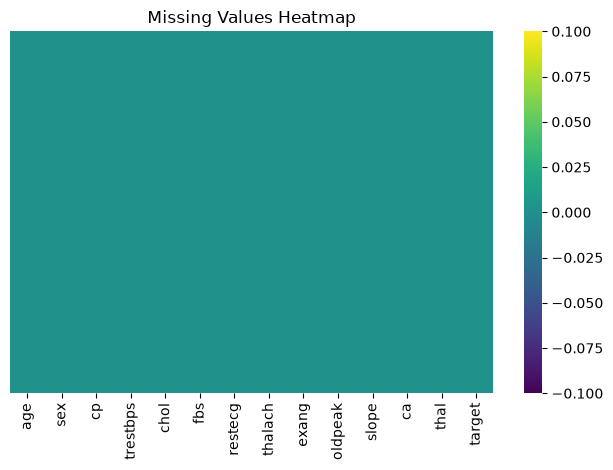

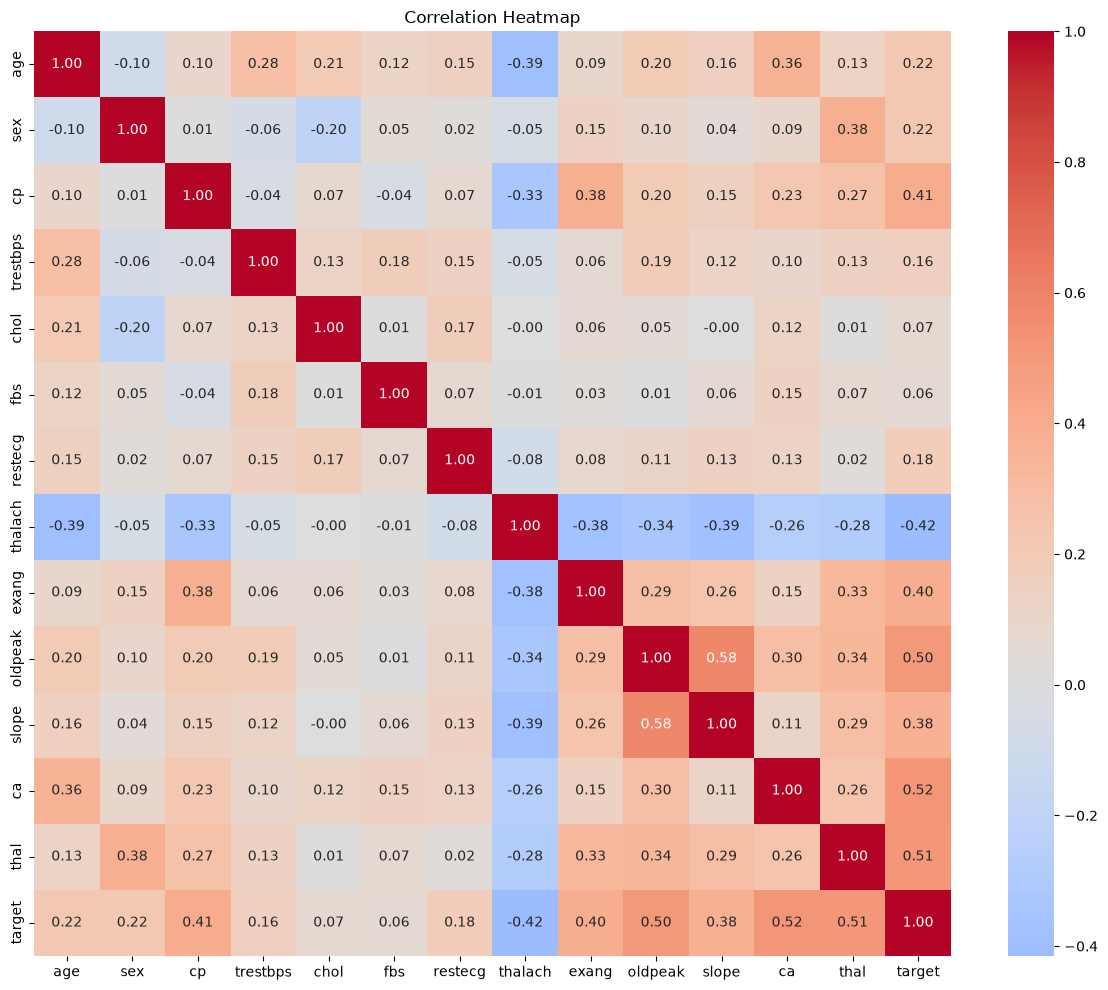

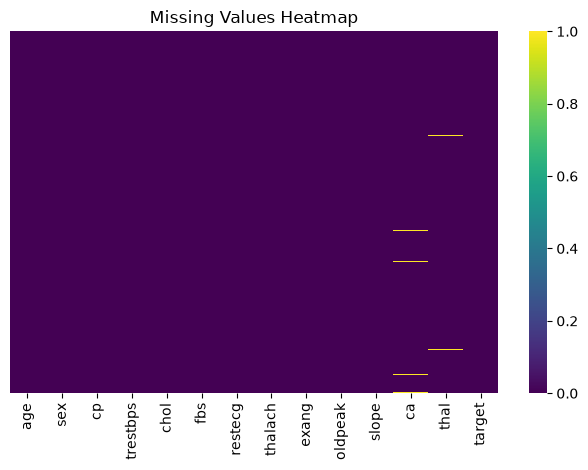

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

data_path =  "../data/raw/heart.csv"
df = pd.read_csv(data_path,header=0)

# Data overview
print(f"Dataset shape: {df.shape}") 
print(f"Data types:\n{df.dtypes}")
print(f"Missing values:\n{df.isnull().sum()}")
print(f"basic statistics:\n{df.describe()}")

#Target variable distribution

plt.figure(figsize=(8,4))
df['target'].value_counts().plot(kind='bar', color='black', alpha=0.7)
plt.title('Heart Disease Target Distribution')
plt.xlabel('Heart Disease Presence (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.tight_layout()
plt.savefig('../data/processed/target_distribution.png')
plt.show()

# Feature distribution for numerical features

flg, axes = plt.subplots(nrows=4, ncols=4, figsize=(16, 14))
axes=axes.ravel()
for idx, col in enumerate(df.columns[:-1]):  # Exclude target variable
    axes[idx].hist(df[col], bins=30, color='black', alpha=0.7)
    axes[idx].set_title(f'Distribution of {col}')
axes[-1].remove()  # Remove the last empty subplot
plt.tight_layout()
plt.savefig('../data/processed/feature_distributions.png')
plt.show()

# Missing value analysis
sns.heatmap(df.isnull(), cbar=True , yticklabels=False, cmap='viridis')
missing_values = (df == '?').sum()
plt.title('Missing Values Heatmap')
plt.tight_layout()
plt.savefig('../data/processed/missing_values.png')
plt.show()

for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Correlation heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap='coolwarm', center=0)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.savefig('../data/processed/correlation_heatmap.png')
plt.show()


# Missing value analysis
sns.heatmap(df.isnull(), cbar=True , yticklabels=False, cmap='viridis')
missing_values = df.isnull().sum()
plt.title('Missing Values Heatmap')
plt.tight_layout()
plt.savefig('../data/processed/missing_values.png')
plt.show()


